# Notebook 02 — Naive Attribution vs. Causal Estimates
## Why Simple Before/After or Treated-vs-Untreated Attribution Is Wrong

**Key insight:** A simple comparison of treated vs. untreated outcomes conflates:
1. The **true causal effect** of the campaign
2. **Selection bias** (who was targeted)
3. **Confounding** (baseline differences between groups)

This notebook computes naive estimates, then shows why they over- or under-state true incrementality.

**Naive methods covered:**
- Simple treatment mean minus control mean
- Before/after (no-control) uplift
- Correlation-based attribution


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120})

df = pd.read_csv('../data/hillstrom_clean.csv')
print(df.shape)

(64000, 20)


## 1. Naive mean difference (treated vs. control)

In [2]:
results = {}
for seg in ['Mens E-Mail', 'Womens E-Mail']:
    treated  = df[df['segment'] == seg]
    control  = df[df['segment'] == 'No E-Mail']
    for outcome in ['visit', 'conversion', 'spend']:
        t_mean = treated[outcome].mean()
        c_mean = control[outcome].mean()
        diff   = t_mean - c_mean
        # two-sample t-test
        tstat, pval = stats.ttest_ind(treated[outcome], control[outcome])
        n_treated    = len(treated)
        se           = np.sqrt(treated[outcome].var()/n_treated + control[outcome].var()/len(control))
        ci_lo, ci_hi = diff - 1.96*se, diff + 1.96*se
        results[(seg, outcome)] = {
            'treated_mean': t_mean, 'control_mean': c_mean,
            'naive_lift': diff, 'CI_lo': ci_lo, 'CI_hi': ci_hi,
            'p_value': pval
        }

naive_df = pd.DataFrame(results).T
naive_df.index.names = ['segment', 'outcome']
print('=== Naive ATE Estimates ===')
naive_df.round(4)

=== Naive ATE Estimates ===


treated_mean  control_mean  naive_lift   CI_lo  \
segment       outcome                                                      
Mens E-Mail   visit             0.1335        0.0775      0.0560  0.0502   
              conversion        0.0608        0.0484      0.0124  0.0081   
              spend             3.3874        2.4417      0.9457  0.6912   
Womens E-Mail visit             0.1430        0.0775      0.0654  0.0595   
              conversion        0.0638        0.0484      0.0154  0.0110   
              spend             3.5706        2.4417      1.1288  0.8688   

                           CI_hi  p_value  
segment       outcome                      
Mens E-Mail   visit       0.0618      0.0  
              conversion  0.0167      0.0  
              spend       1.2001      0.0  
Womens E-Mail visit       0.0714      0.0  
              conversion  0.0198      0.0  
              spend       1.3889      0.0

## 2. Visualise naive lift with confidence intervals

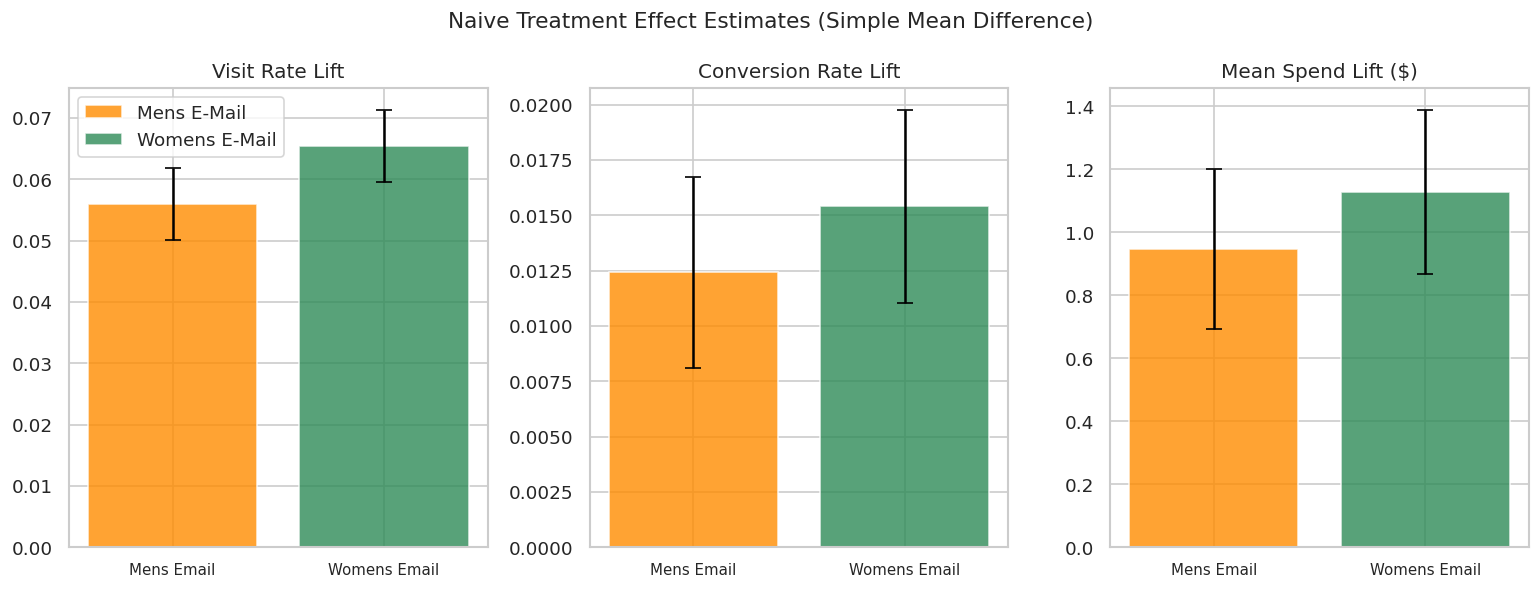

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
outcomes = ['visit', 'conversion', 'spend']
titles   = ['Visit Rate Lift', 'Conversion Rate Lift', 'Mean Spend Lift ($)']
colors   = {'Mens E-Mail': 'darkorange', 'Womens E-Mail': 'seagreen'}

for ax, outcome, title in zip(axes, outcomes, titles):
    for i, seg in enumerate(['Mens E-Mail', 'Womens E-Mail']):
        row  = naive_df.loc[(seg, outcome)]
        lift = float(row['naive_lift'])
        lo   = float(row['CI_lo'])
        hi   = float(row['CI_hi'])
        ax.bar(i, lift, color=colors[seg], alpha=0.8, label=seg)
        ax.errorbar(i, lift, yerr=[[lift-lo],[hi-lift]], fmt='none', color='black', capsize=5)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(title)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Mens Email', 'Womens Email'], fontsize=9)

axes[0].legend()
plt.suptitle('Naive Treatment Effect Estimates (Simple Mean Difference)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/02_naive_attribution.png', bbox_inches='tight')
plt.show()

## 3. Why naive estimates are biased: confounding demonstration

Baseline conversion predictability from covariates alone (control group AUC): 0.600

This means customer characteristics predict conversion probability even without a campaign.
If treated customers differ on these characteristics, naive lift estimates are biased.


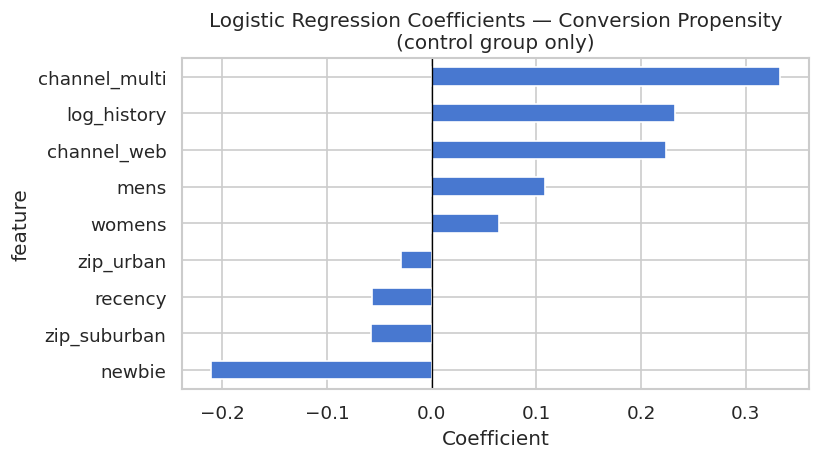

In [4]:
# Demonstrate that covariates predict outcomes EVEN within control group
# — so any covariate imbalance between arms creates bias
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

FEATURE_COLS = ['recency', 'log_history', 'mens', 'womens', 'newbie',
                'channel_web', 'channel_multi', 'zip_urban', 'zip_suburban']

ctrl = df[df['segment'] == 'No E-Mail'].copy()
X, y = ctrl[FEATURE_COLS], ctrl['conversion']

lr = LogisticRegression(max_iter=500)
lr.fit(X, y)
auc = roc_auc_score(y, lr.predict_proba(X)[:,1])

print(f'Baseline conversion predictability from covariates alone (control group AUC): {auc:.3f}')
print('\nThis means customer characteristics predict conversion probability even without a campaign.')
print('If treated customers differ on these characteristics, naive lift estimates are biased.')

coef_df = pd.DataFrame({'feature': FEATURE_COLS, 'coefficient': lr.coef_[0]}).sort_values('coefficient')
fig, ax = plt.subplots(figsize=(7, 4))
coef_df.plot(kind='barh', x='feature', y='coefficient', ax=ax, legend=False)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression Coefficients — Conversion Propensity\n(control group only)')
ax.set_xlabel('Coefficient')
plt.tight_layout()
plt.savefig('../outputs/02_propensity_coefficients.png', bbox_inches='tight')
plt.show()

## Key takeaway

> **Naive attribution overstates lift** for segments that were already more likely to convert, and understates it for less engaged segments. The correct approach — used in Notebooks 03-05 — conditions on observed covariates (PSM, regression adjustment) or leverages the randomisation design (DiD) to isolate the causal effect.
